**PROYECTO: Modelado espacial para estimar la susceptibilidad a inundaciones usando algoritmos de aprendizaje automatico con datos geomorfologicos**

Autor: Sebastian Velosa Bohorquez. Curso: Percepción Remota Avanzada.

**NOTEBOOK 04/07**

# Variables topográficas e hidrológicas derivadas de DEM/DTM
(Copernicus GLO 30)

**Objetivo:**
Este notebook genera, desde un DEM COPERNICUS GLO 30, las siguientes capas alineadas píxel a píxel:

- `Elevation`: elevación original.
- `Slope`: pendiente en grados.
- `HAND`: altura sobre el drenaje derivado del DEM.
- `FlowAccumulation`: número de celdas contribuyentes.
- `DistRiver`: distancia a la red de drenaje derivada o a una capa hidrográfica suministrada.
- `TWI`: índice topográfico de humedad aproximado.
- `Curvature`: curvatura general calculada a partir de derivadas del DEM.
- `TPI`: posición topográfica relativa.
- `TRI`: índice de rugosidad del terreno.


**Resolución objetivo:** 30 × 30 m. Todas las salidas se calculan sobre la misma cuadrícula del DEM de referencia, y al final se crea un stack multibanda.



***Contenido:***
1. Instalar librerías
2. Cargar los archivos
3. Revisar el DEM y fijar parámetros
4. Preparar archivos de trabajo y DEM hidrológico
5. Calculo de SLOPE, Flow Accumulation y Streams (Red de Drenaje derivada)
6. Calcular HAND
7. Calcular DistRiver
8. Calcular TWI, Curvature, TPI y TRI
9. Crear el stack multibanda
10. Revisar que todas las capas estén alineadas
11. Visualizar las variables
12. Descargar resultados

**RESULTADOS:**

Un archivo zip con rasters individuales de 9 variables geomorfologicas y un raster multibanda.

* resultados_variables_topograficas_COPERNICUS_GLO_30.zip

### Antes de ejecutar

**Datos:** COPERNICUS GLO 30 DEM, FABDEM, ANADEM previamente armonizados. Formato `.tiff`

1. Usa un DEM PREVIAMENTE ARMONIZADO.
2. Subir la capa hidrográfica en SHP,  comprimida como ZIP con todos sus archivos (`.shp`, `.shx`, `.dbf`, `.prj`), o como GeoPackage (`.gpkg`). **Es opcional.**
3. Para HAND y Flow Accumulation se deriva una red de drenaje del DEM mediante un umbral de acumulación. La capa hidrográfica opcional se usa para `DistRiver` y para comparación visual; no reemplaza automáticamente la red hidrológica derivada.
4. En planicies con ciénagas, lagunas, diques y canales, no rellenes depresiones indiscriminadamente sin revisar los resultados. Este notebook crea un DEM rellenado para el cálculo hidrológico, pero conserva el DEM original para las variables de elevación y terreno. Revisa las depresiones y la red derivada antes de interpretar HAND.
5. **Una vez terminado el proceso, se puede ejecutar nuevamente el notebook por separado utilizando otro de los DEM/DTM asignados para el estudio y manteniendo los mismo parametros**

**Limitación importante:** HAND es sensible a la calidad del DEM, al algoritmo hidrológico y al umbral usado para definir los drenajes. Los resultados deben validarse frente a la cartografía hidrográfica y las imágenes disponibles.

## 1. Instalar librerías

WhiteboxTools se usa para el procesamiento hidrológico. Rasterio, SciPy y NumPy se usan para leer y calcular variables ráster.

In [ ]:
!pip -q install whitebox rasterio geopandas scipy matplotlib

## 2. Cargar los archivos

Sube **un DEM GeoTIFF** (`.tif` o `.tiff`). Opcionalmente, sube una capa hidrográfica: un `.gpkg` o un `.zip` que contenga el shapefile completo de la red hidrologica.

**Se puede ejecutar el notebook por separado para cada DEM manteniendo los mismos parámetros.** Para compararlos, primero deben estar en la misma proyección, resolución, extensión y alineación.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Carga de archivo DEM/DTM:

In [ ]:
# EDITAR estas rutas para repetir el proceso con otro DEM al finalizar

dem_path = (
    '/content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/DEM_alineados/Copernicus_GLO30_Sinu_alineado.tif'
)


In [ ]:
import os, zipfile, glob, shutil
from pathlib import Path

import os

if os.path.exists(dem_path):
    print("DEM encontrado:", dem_path)
else:
    print("Revisa la ruta y el nombre del archivo.")

DEM encontrado: /content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/DEM_alineados/Copernicus_GLO30_Sinu_alineado.tif


Carga de archivo con red hidrográfica:

In [ ]:
from google.colab import files
uploaded = files.upload()


# Extraer shapefile si se subió como ZIP
vector_path = None
for f in uploaded:
    if f.lower().endswith(".gpkg"):
        vector_path = f
        break
    if f.lower().endswith(".zip"):
        with zipfile.ZipFile(f, "r") as z:
            z.extractall("vector_extraido")
        shp_files = glob.glob("vector_extraido/**/*.shp", recursive=True)
        if shp_files:
            vector_path = shp_files[0]
            break

if vector_path:
    print("Capa hidrográfica:", vector_path)
else:
    print("No se detectó capa vectorial. DistRiver se calculará respecto a la red derivada del DEM.")

Saving Drenaje_Doble_clip.zip to Drenaje_Doble_clip (2).zip
Capa hidrográfica: vector_extraido/Drenaje_Doble_clip.shp


## 3. Revisar el DEM y fijar parámetros

El DEM/DTM `"*_alineado.tiff"` fue  proyectado a trabajar en metros con el sistema de coordenadas EPSG:31972, SIRGAS 2000 / UTM zona 18N en un notebook anterior. Si está en coordenadas geográficas (grados), reproyéctalo antes de continuar. No es correcto calcular distancias o áreas directamente en grados.

El umbral de acumulación controla qué celdas se consideran drenajes. `1000` celdas equivale aproximadamente a 0,9 km² con píxeles de 30 m, antes de considerar la convención de conteo del algoritmo.

CRS: EPSG:31972
Resolución: (30.0, 30.0)
Dimensiones: 3103 x 3848
NoData: -9999.0
Elevación mínima: 1.538727
Elevación máxima: 195.14594


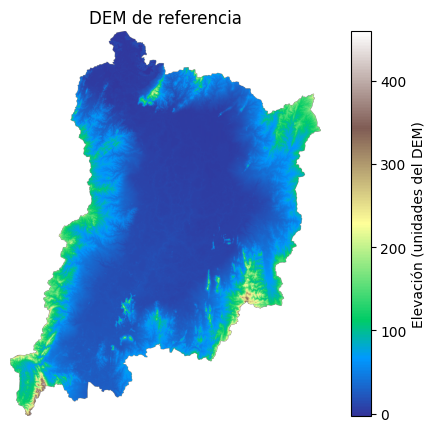

Umbral de drenaje: 1000
Ventana TPI: 11 píxeles


In [ ]:
import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
import matplotlib.pyplot as plt

with rasterio.open(dem_path) as src:
    dem = src.read(1).astype("float32")
    profile = src.profile.copy()
    transform = src.transform
    crs = src.crs
    nodata = src.nodata
    bounds = src.bounds
    print("CRS:", crs)
    print("Resolución:", src.res)
    print("Dimensiones:", src.width, "x", src.height)
    print("NoData:", nodata)

if crs is None:
    raise ValueError("El DEM no tiene CRS definido.")
if crs.is_geographic:
    raise ValueError("El DEM está en coordenadas geográficas (grados). Reproyéctalo a un CRS proyectado en metros antes de continuar.")
if abs(abs(transform.a) - 30) > 1 or abs(abs(transform.e) - 30) > 1:
    print("AVISO: el tamaño de píxel no parece ser 30 m. Se conservará la cuadrícula de entrada; reproyecta/remuestrea antes si necesitas exactamente 30 m.")

valid = np.isfinite(dem)
if nodata is not None:
    valid &= (dem != nodata)
dem[~valid] = np.nan

print("Elevación mínima:", np.nanpercentile(dem, 1))
print("Elevación máxima:", np.nanpercentile(dem, 99))

plt.figure(figsize=(8, 5))
plt.imshow(dem, cmap="terrain")
plt.colorbar(label="Elevación (unidades del DEM)")
plt.title("DEM de referencia")
plt.axis("off")
plt.show()

# Parámetros que puedes modificar
FLOW_THRESHOLD = 1000  # celdas contribuyentes; probar varios valores
TPI_WINDOW = 11        # ventana impar; 11 píxeles = aprox. 330 m de ancho
TRI_WINDOW = 3         # ventana local para rugosidad
print("Umbral de drenaje:", FLOW_THRESHOLD)
print("Ventana TPI:", TPI_WINDOW, "píxeles")

## 4. Preparar archivos de trabajo y DEM hidrológico

Se guarda una copia temporal del DEM con NoData convertido a un valor reconocido por WhiteboxTools. El relleno de depresiones se aplica **solo a la copia hidrológica**, no al DEM usado para Elevation.

En una planicie aluvial, el relleno puede borrar depresiones reales de ciénagas y lagunas.

## 5. Calculo de SLOPE, Flow Accumulation y Streams (Red de Drenaje derivada)

La pendiente se calcula en grados. La acumulación se expresa como número de celdas contribuyentes. La red de drenaje se deriva usando el umbral configurado arriba.

In [ ]:
from whitebox import WhiteboxTools

workdir = os.path.abspath('procesamiento_dem')
os.makedirs(workdir, exist_ok=True)
wbt = WhiteboxTools()
wbt.set_working_dir(os.getcwd())
wbt.verbose = True

# Perfil limpio:
work_profile = profile.copy()
for key in ['blockxsize', 'blockysize', 'tiled']:
    work_profile.pop(key, None)
work_profile.update(driver='GTiff', dtype='float32', count=1,
                    nodata=-9999.0, compress='lzw')

dem_work = os.path.join(workdir, 'dem_original.tif')
dem_hydro = os.path.join(workdir, 'dem_hidrologico.tif')
with rasterio.open(dem_work, 'w', **work_profile) as dst:
    dst.write(np.where(valid, dem, -9999).astype('float32'), 1)

# Preparar el DEM para el flujo
wbt.fill_depressions(dem_work, dem_hydro)

slope_path = os.path.join(workdir, 'Slope.tif')
flowacc_path = os.path.join(workdir, 'FlowAccumulation.tif')
streams_path = os.path.join(workdir, 'Streams.tif')
hand_path = os.path.join(workdir, 'HAND.tif')
pointer_path = os.path.join(workdir, 'D8_pointer.tif')

wbt.slope(dem_work, slope_path, zfactor=1.0)
wbt.d8_pointer(dem_hydro, pointer_path)
wbt.d8_flow_accumulation(dem_hydro, flowacc_path, out_type='cells')
wbt.extract_streams(flowacc_path, streams_path, threshold=FLOW_THRESHOLD)
wbt.elevation_above_stream(dem_hydro, streams_path, hand_path)

# Detenerse aquí si falta algún producto
required = [slope_path, flowacc_path, streams_path, hand_path]
missing = [p for p in required if not os.path.exists(p)]
if missing:
    raise FileNotFoundError('WhiteboxTools no creó estos archivos: ' + str(missing))
print('Correcto: Slope, Flow Accumulation, Streams y HAND creados.')

./whitebox_tools --run="FillDepressions" --wd="/content" --dem='/content/procesamiento_dem/dem_original.tif' --output='/content/procesamiento_dem/dem_hidrologico.tif' --fix_flats -v --compress_rasters=False

******************************
* Welcome to FillDepressions *
* Powered by WhiteboxTools   *
* www.whiteboxgeo.com        *
******************************
Reading data...
Finding pit cells: 50%
Finding pit cells: 100%
Filling depressions: 0%
Filling depressions: 1%
Filling depressions: 2%
Filling depressions: 3%
Filling depressions: 4%
Filling depressions: 5%
Filling depressions: 6%
Filling depressions: 7%
Filling depressions: 8%
Filling depressions: 9%
Filling depressions: 10%
Filling depressions: 11%
Filling depressions: 12%
Filling depressions: 13%
Filling depressions: 14%
Filling depressions: 15%
Filling depressions: 16%
Filling depressions: 17%
Filling depressions: 18%
Filling depressions: 19%
Filling depressions: 20%
Filling depressions: 21%
Filling depressions: 22%
Filling d

## 6. Calcular HAND

HAND se calcula respecto a la red de drenaje derivada de la acumulación. El resultado expresa la diferencia vertical entre cada celda y el drenaje al que se conecta según la dirección de flujo.

Si la red derivada no representa los caños o conexiones de las ciénagas, HAND puede ser poco realista en esas zonas. Ajusta el umbral y compara con cartografía e imágenes antes de usarlo en el modelo.

In [ ]:
hand_path = os.path.join(workdir, "HAND.tif")
wbt.elevation_above_stream(dem_hydro, streams_path, hand_path)
print("HAND calculado:", hand_path)

./whitebox_tools --run="ElevationAboveStream" --wd="/content" --dem='/content/procesamiento_dem/dem_hidrologico.tif' --streams='/content/procesamiento_dem/Streams.tif' --output='/content/procesamiento_dem/HAND.tif' -v --compress_rasters=False

***********************************
* Welcome to ElevationAboveStream *
* Powered by WhiteboxTools        *
* www.whiteboxgeo.com             *
***********************************
Reading DEM data...
Reading streams data...
Flow directions: 0%
Flow directions: 1%
Flow directions: 2%
Flow directions: 3%
Flow directions: 4%
Flow directions: 5%
Flow directions: 6%
Flow directions: 7%
Flow directions: 8%
Flow directions: 9%
Flow directions: 10%
Flow directions: 11%
Flow directions: 12%
Flow directions: 13%
Flow directions: 14%
Flow directions: 15%
Flow directions: 16%
Flow directions: 17%
Flow directions: 18%
Flow directions: 19%
Flow directions: 20%
Flow directions: 21%
Flow directions: 22%
Flow directions: 23%
Flow directions: 24%
Flow directions: 

## 7. Calcular DistRiver

Si cargo una capa vectorial anteriormente, se rasteriza la presencia de sus geometrías sobre la cuadrícula del DEM y se calcula la distancia euclidiana en metros a la celda más cercana marcada como agua/cauce. Si no subiste capa, se usa la red derivada (`Streams.tif`).

**Nota:** si el vector es un polígono ancho de río/ciénaga, la distancia resultante será distancia al borde o a la superficie rasterizada, no necesariamente al eje central del cauce.

In [ ]:
dist_path = os.path.join(workdir, 'DistRiver.tif')

if vector_path:
    gdf = gpd.read_file(vector_path)
    if gdf.crs is None:
        raise ValueError('La capa hidrográfica no tiene CRS definido.')
    gdf = gdf.to_crs(crs)
    shapes = [(g, 1) for g in gdf.geometry if g is not None and not g.is_empty]
    water = rasterize(shapes, out_shape=dem.shape, transform=transform,
                      fill=0, all_touched=True, dtype='uint8').astype(bool)
    source_name = 'capa vectorial'
else:
    with rasterio.open(streams_path) as src:
        water = src.read(1) > 0
    source_name = 'red derivada del DEM'

if not water.any():
    raise ValueError('No se encontraron celdas de hidrografía para DistRiver.')

dist = distance_transform_edt(~water, sampling=(pixel_y, pixel_x)).astype('float32')
dist[~valid] = np.nan
with rasterio.open(dist_path, 'w', **work_profile) as dst:
    dst.write(np.where(np.isfinite(dist), dist, -9999).astype('float32'), 1)
print('DistRiver calculado usando:', source_name)

DistRiver calculado usando: capa vectorial


## 8. Calcular TWI, Curvature, TPI y TRI

- **TWI:** aproximación `ln((área contribuyente por unidad de contorno) / tan(pendiente))`. Se usa acumulación de flujo y pendiente. Los valores dependen de la definición de área contribuyente y del tratamiento de pendientes muy pequeñas.
- **Curvature:** curvatura general aproximada a partir de derivadas de segundo orden del DEM.
- **TPI:** elevación de cada celda menos la elevación media de una ventana vecina.
- **TRI:** raíz de la media de las diferencias cuadráticas entre una celda y sus vecinas en una ventana 3 × 3.

**Las ventanas de TPI/TRI deben mantenerse iguales entre los DEM que se comparen.**

In [ ]:
def leer(path):
    with rasterio.open(path) as src:
        a = src.read(1).astype('float32')
        if src.nodata is not None:
            a[a == src.nodata] = np.nan
        return a

slope = leer(slope_path)
flowacc = leer(flowacc_path)
hand = leer(hand_path)

# TPI: elevación menos media local, sin promediar NoData
mask = np.isfinite(dem).astype('float32')
media_num = uniform_filter(np.nan_to_num(dem, nan=0.0), size=TPI_WINDOW, mode='nearest')
media_den = uniform_filter(mask, size=TPI_WINDOW, mode='nearest')
media_local = np.divide(media_num, media_den, out=np.full_like(dem, np.nan), where=media_den > 0)
tpi = dem - media_local

# TRI: promedio de diferencias cuadráticas con vecinos en ventana 3x3
suma = np.zeros_like(dem, dtype='float32')
cuenta = np.zeros_like(dem, dtype='float32')
for dy in (-1, 0, 1):
    for dx in (-1, 0, 1):
        if dy == 0 and dx == 0:
            continue
        vecino = np.full_like(dem, np.nan)
        y1, y2 = max(0, dy), dem.shape[0] + min(0, dy)
        x1, x2 = max(0, dx), dem.shape[1] + min(0, dx)
        vecino[y1:y2, x1:x2] = dem[y1-dy:y2-dy, x1-dx:x2-dx]
        ok = np.isfinite(dem) & np.isfinite(vecino)
        suma[ok] += (dem[ok] - vecino[ok])**2
        cuenta[ok] += 1
tri = np.sqrt(np.divide(suma, cuenta, out=np.full_like(suma, np.nan), where=cuenta > 0))

# Curvatura general aproximada a partir de segundas derivadas
safe_dem = np.where(valid, dem, np.nanmedian(dem))
dz_dy, dz_dx = np.gradient(safe_dem, pixel_y, pixel_x)
curvature = np.gradient(dz_dx, pixel_x, axis=1) + np.gradient(dz_dy, pixel_y, axis=0)
curvature[~valid] = np.nan

# TWI aproximado; las pendientes muy pequeñas se limitan para evitar infinitos
slope_rad = np.deg2rad(np.clip(slope, 0.01, 89.9))
area_specific = np.maximum(flowacc, 1) * pixel_x
with np.errstate(invalid='ignore', divide='ignore'):
    twi = np.log(np.maximum(area_specific, 1e-6) / np.maximum(np.tan(slope_rad), 1e-6))

for a in [slope, flowacc, hand, dist, twi, curvature, tpi, tri]:
    a[~valid] = np.nan
print('Variables calculadas.')

Variables calculadas.


## 9. Crear el stack multibanda

Se escriben todas las variables en un único GeoTIFF multibanda y también como archivos individuales. **Cada banda conserva exactamente las mismas dimensiones, transformación, CRS y resolución**, porque se deriva de la cuadrícula del DEM de referencia.

Los valores NoData se escriben como `-9999`. La banda `FlowAccumulation` se guarda como Float32 para mantener un tipo común en el stack; sus valores representan conteos de celdas.

In [ ]:
variables = {
    'Elevation': dem,
    'Slope': slope,
    'HAND': hand,
    'FlowAccumulation': flowacc,
    'DistRiver': dist,
    'TWI': twi,
    'Curvature': curvature,
    'TPI': tpi,
    'TRI': tri
}

out_dir = os.path.abspath('resultados_variables')
os.makedirs(out_dir, exist_ok=True)
out_profile = work_profile.copy()

for name, arr in variables.items():
    path = os.path.join(out_dir, name + '.tif')
    with rasterio.open(path, 'w', **out_profile) as dst:
        dst.write(np.where(np.isfinite(arr), arr, -9999).astype('float32'), 1)

stack_path = os.path.join(out_dir, 'Stack_topografico_hidrologico.tif')
stack_profile = out_profile.copy()
stack_profile.update(count=len(variables))
with rasterio.open(stack_path, 'w', **stack_profile) as dst:
    for i, (name, arr) in enumerate(variables.items(), start=1):
        dst.write(np.where(np.isfinite(arr), arr, -9999).astype('float32'), i)
        dst.set_band_description(i, name)

print('Stack creado:', stack_path)
print('Orden de bandas:', list(variables.keys()))

Stack creado: /content/resultados_variables/Stack_topografico_hidrologico.tif
Orden de bandas: ['Elevation', 'Slope', 'HAND', 'FlowAccumulation', 'DistRiver', 'TWI', 'Curvature', 'TPI', 'TRI']


## 10. Revisar que todas las capas estén alineadas

Esta celda comprueba que los archivos individuales tengan igual tamaño, CRS y transformación. También imprime estadísticas básicas para detectar resultados extraños.

Bandas: 9
Dimensiones: 3103 x 3848
Resolución: (30.0, 30.0)
CRS: EPSG:31972
Nombres: ('Elevation', 'Slope', 'HAND', 'FlowAccumulation', 'DistRiver', 'TWI', 'Curvature', 'TPI', 'TRI')


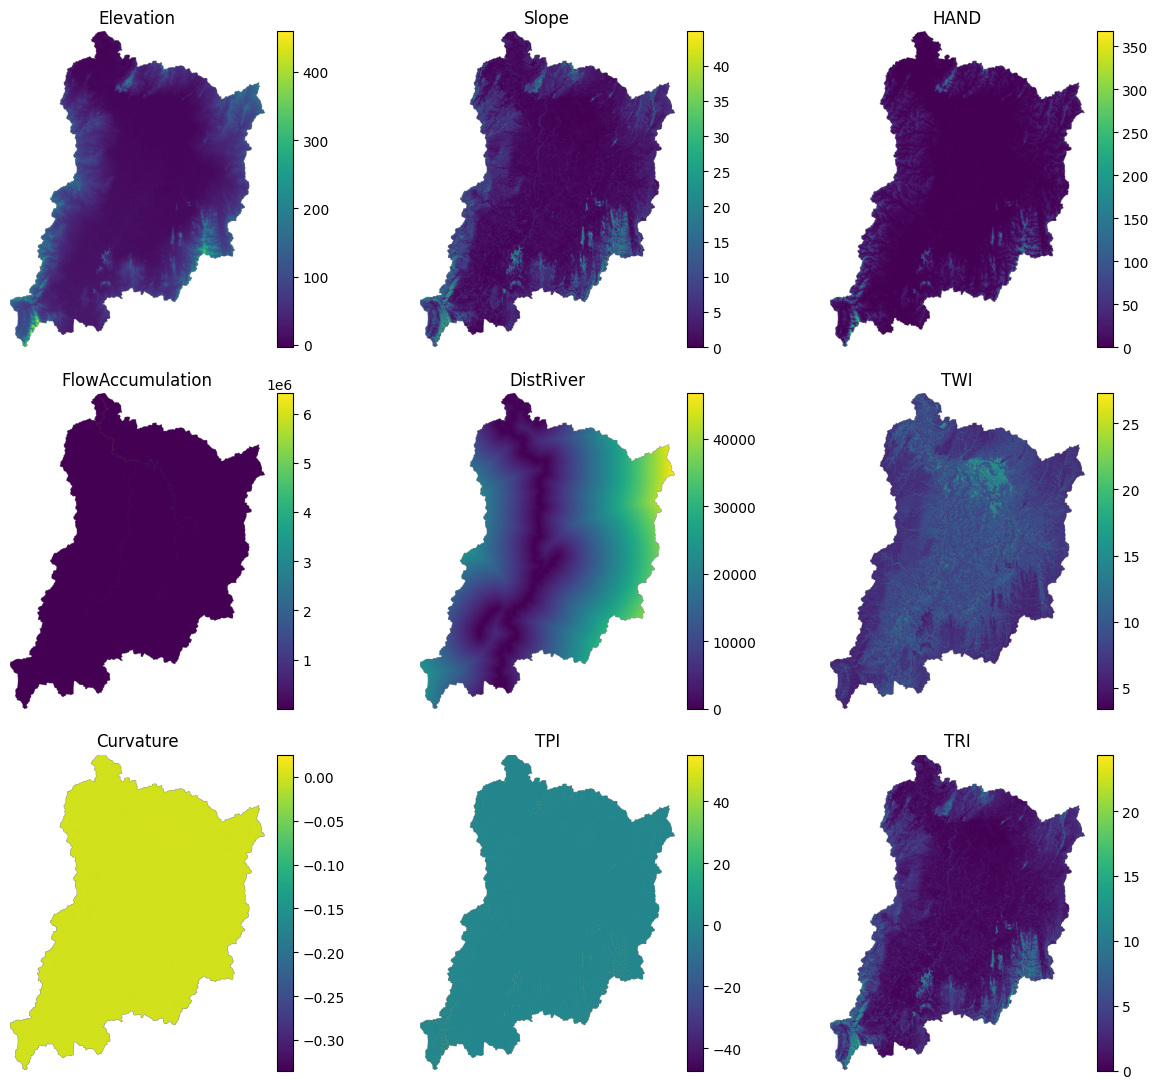

In [ ]:
with rasterio.open(stack_path) as src:
    print('Bandas:', src.count)
    print('Dimensiones:', src.width, 'x', src.height)
    print('Resolución:', src.res)
    print('CRS:', src.crs)
    print('Nombres:', src.descriptions)

fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for ax, (name, arr) in zip(axes.ravel(), variables.items()):
    im = ax.imshow(arr, cmap='viridis')
    ax.set_title(name)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
plt.tight_layout()
plt.show()

## 11. Visualizar las variables

Se muestran mapas rápidos para revisar patrones espaciales y detectar errores evidentes. La visualización no reemplaza la validación hidrológica.

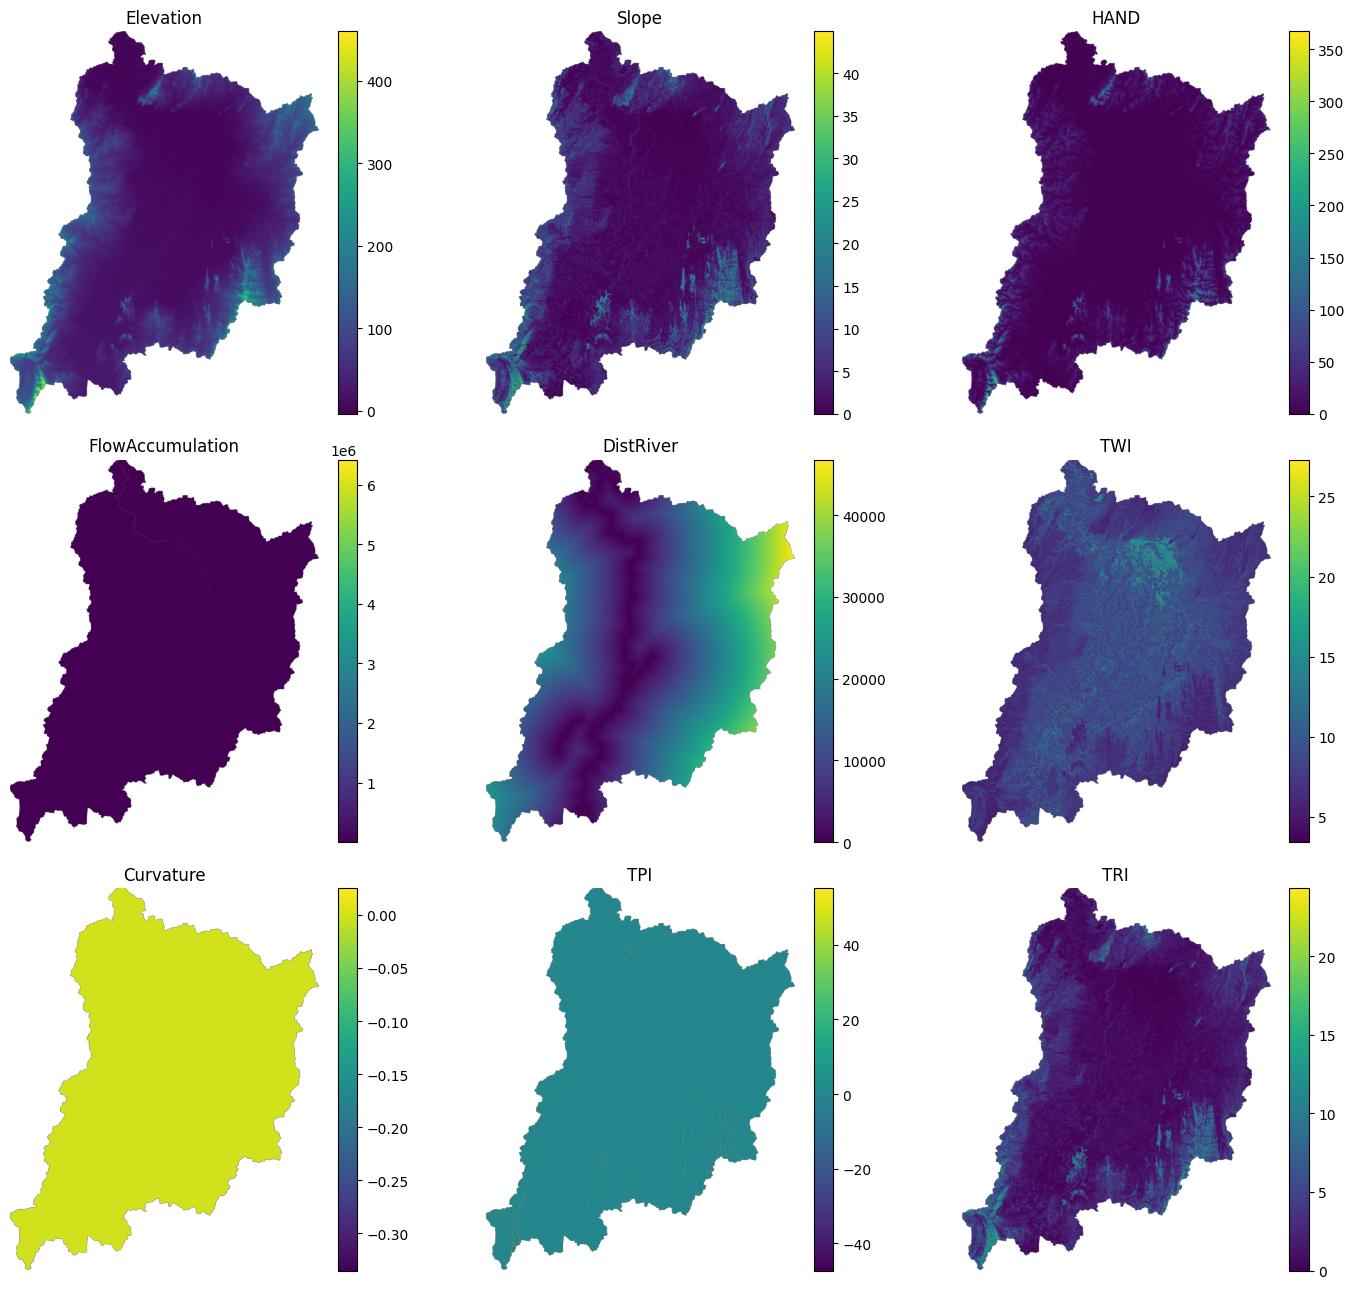

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for ax, (name, arr) in zip(axes.ravel(), variables.items()):
    im = ax.imshow(arr, cmap="viridis")
    ax.set_title(name)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 12. Descargar resultados

Se comprime la carpeta con las capas individuales, el stack y sus nombres de banda.

In [ ]:
import shutil
zip_path = shutil.make_archive("resultados_variables_topograficas_COPERNICUS_GLO_30", "zip", out_dir) # Editar nombre segun el DEM/DTM a trabajar
print("Archivo listo:", zip_path)

from google.colab import files
files.download(zip_path)

Archivo listo: /content/resultados_variables_topograficas_COPERNICUS_GLO_30.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>